# PNM Generation and Mercury Intrusion Simulation




This notebook demonstrates how to generate a random pore network model (PNM)
from experimental mercury intrusion porosimetry (MIP) data, compare the generated
network against the experimental distributions, run a mercury intrusion simulation,
and visualize the resulting 3D network.

**Workflow:**
1. Read experimental source files (CSV)
2. Prepare experimental data: pore diameter threshold, cumulative pore/throat distributions
3. Define model parameters (number of pores, surface coverage ratio, corrective factor `e`, PRTRR)
4. Generate one or more pore networks
5. Compare experimental vs generated distributions (pores and throats)
6. Mercury intrusion simulation: compare experimental vs simulated intrusion curves
7. 3D visualization and image saving

Generated networks are saved in `examples/networks/`.



## 1. Imports and Configuration



In [1]:
# Add project root to Python path so the 'pnm' package can be imported
import sys
from pathlib import Path
sys.path.insert(0, "/home/jlux/Nextcloud/Codes/python3/pnm")

import os
import csv
import numpy as np
import matplotlib.pyplot as plt
from functools import partial

# Plotting inline
%matplotlib inline

# PNM package
import pnm
from pnm import pore_network
from pnm.Generators import random_PNM
from pnm.Algorithms.percolation import mercury_intrusion
from pnm.Stats import stats

# Project paths
PROJECT_ROOT = Path("/home/jlux/Nextcloud/Codes/python3/pnm")
DATA_DIR = PROJECT_ROOT / "examples" / "data"
NETWORKS_DIR = PROJECT_ROOT / "examples" / "networks"
NETWORKS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project root: {PROJECT_ROOT}")
print(f"Data directory: {DATA_DIR}")
print(f"Networks directory: {NETWORKS_DIR}")


Project root: /home/jlux/Nextcloud/Codes/python3/pnm
Data directory: /home/jlux/Nextcloud/Codes/python3/pnm/examples/data
Networks directory: /home/jlux/Nextcloud/Codes/python3/pnm/examples/networks


## 2. Read Source Files




The `examples/data/` directory contains CSV files with mercury intrusion porosimetry
data. Each file has two columns: pore **diameter** and **intruded volume**.

Available files:



In [2]:
csv_files = sorted([f for f in os.listdir(DATA_DIR) if f.endswith(".csv")])
for f in csv_files:
    print(f"  - {f}")


  - GM1.csv
  - GM2-EMPA.csv
  - GM2.csv
  - MP.csv
  - PCI.csv
  - PCV.csv


### Load the first CSV file (GM1)



In [3]:
selected_file = csv_files[0]
filepath = DATA_DIR / selected_file
print(f"Loading: {filepath}")

diameters = []
volumes = []
with open(filepath, "r", newline="") as infile:
    reader = csv.reader(infile, delimiter=";")
    header = next(reader)  # skip header
    print(f"Header: {header}")
    for row in reader:
        if len(row) >= 2:
            diameters.append(float(row[0]))
            volumes.append(float(row[1]))

diameters = np.array(diameters)
volumes = np.array(volumes)
print(f"Loaded {len(diameters)} data points")
print(f"Diameter range: {diameters.min():.3f} - {diameters.max():.3f}")
print(f"Total volume: {volumes.sum():.6f}")


Loading: /home/jlux/Nextcloud/Codes/python3/pnm/examples/data/GM1.csv
Header: ['\ufeffDiameter', 'Volume']
Loaded 47 data points
Diameter range: 0.006 - 355.307
Total volume: 0.940580


## 3. Prepare Experimental Data




### Pore diameter threshold

We apply a threshold on pore diameter based on the cumulative probability.
Pores below the threshold are considered too small to be resolved and are excluded.

### Cumulative distributions

We compute the cumulative volume distribution for pores and derive the
corresponding throat distribution assuming a constant average throat length
for all diameters.



In [4]:
# Sort by diameter (ascending)
sort_idx = np.argsort(diameters)
diameters = diameters[sort_idx]
volumes = volumes[sort_idx]

# Cumulative volume fraction
cum_volumes = np.cumsum(volumes)
cum_volumes_norm = cum_volumes / cum_volumes[-1]

# Threshold: keep pores that represent at least 'threshold_frac' of cumulative volume
threshold_frac = 0.99  # keep 99% of the cumulative volume
threshold_idx = np.searchsorted(cum_volumes_norm, threshold_frac)
threshold_diameter = diameters[threshold_idx]
print(f"Threshold diameter (keep {threshold_frac*100:.0f}% cum. vol.): {threshold_diameter:.4f}")

# Apply threshold
mask = diameters >= threshold_diameter
diameters_f = diameters[mask]
volumes_f = volumes[mask]
print(f"Pores after threshold: {len(diameters_f)} (from {len(diameters)})")


Threshold diameter (keep 99% cum. vol.): 33.0383
Pores after threshold: 5 (from 47)


### Pore radius bins and distributions



In [5]:
# Pore radii (diameter / 2)
pore_radii = diameters_f / 2.0

# Define radius bins (log-spaced)
n_bins = 30
rbins = np.geomspace(pore_radii.min() * 0.5, pore_radii.max() * 2.0, n_bins + 1)
deltaR = np.diff(rbins)
midradii = rbins[:-1] + deltaR * 0.5

# Pore volume distribution (histogram)
pore_hist, _ = np.histogram(pore_radii, bins=rbins, weights=volumes_f)
pore_hist_norm = pore_hist / pore_hist.sum()
pore_cumdist = np.cumsum(pore_hist_norm)

# Throat distribution (assuming constant average throat length)
# Empirical corrective factor e (no correction: e=1)
e = 1.0
throat_volumes = volumes_f / (np.pi * (pore_radii**2 + (1.0/3) * (pore_radii[1]-pore_radii[0])**2)**e)
throat_hist, _ = np.histogram(pore_radii, bins=rbins, weights=throat_volumes)
throat_hist_norm = throat_hist / throat_hist.sum()
throat_cumdist = np.cumsum(throat_hist_norm)

print(f"Number of radius bins: {n_bins}")
print(f"Radius range: {rbins[0]:.4f} - {rbins[-1]:.4f}")


Number of radius bins: 30
Radius range: 8.2596 - 355.3070


### Visualization of experimental distributions



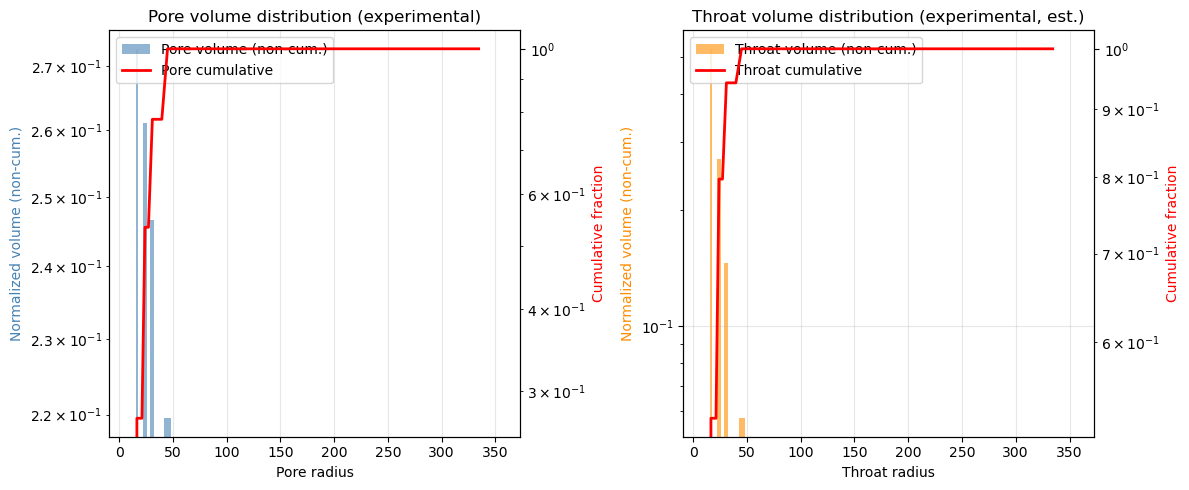

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# --- Pore volume distribution ---
# Left axis: non-cumulative volume distribution (bars)
# Right axis: cumulative distribution (line)
bars1 = ax1.bar(midradii, pore_hist_norm, width=deltaR, alpha=0.6,
                label='Pore volume (non-cum.)', color='steelblue')
ax1_cum = ax1.twinx()
line1, = ax1_cum.plot(midradii, pore_cumdist, 'r-', lw=2,
                      label='Pore cumulative')
ax1.set_xlabel('Pore radius')
ax1.set_ylabel('Normalized volume (non-cum.)', color='steelblue')
ax1_cum.set_ylabel('Cumulative fraction', color='red')
ax1.set_title('Pore volume distribution (experimental)')
ax1.set_yscale('log')
ax1_cum.set_yscale('log')
ax1.grid(True, alpha=0.3)
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax1_cum.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc='upper left')

# --- Throat volume distribution ---
bars2 = ax2.bar(midradii, throat_hist_norm, width=deltaR, alpha=0.6,
                label='Throat volume (non-cum.)', color='darkorange')
ax2_cum = ax2.twinx()
line2, = ax2_cum.plot(midradii, throat_cumdist, 'r-', lw=2,
                      label='Throat cumulative')
ax2.set_xlabel('Throat radius')
ax2.set_ylabel('Normalized volume (non-cum.)', color='darkorange')
ax2_cum.set_ylabel('Cumulative fraction', color='red')
ax2.set_title('Throat volume distribution (experimental, est.)')
ax2.set_yscale('log')
ax2_cum.set_yscale('log')
ax2.grid(True, alpha=0.3)
h1, l1 = ax2.get_legend_handles_labels()
h2, l2 = ax2_cum.get_legend_handles_labels()
ax2.legend(h1 + h2, l1 + l2, loc='upper left')

plt.tight_layout()
plt.show()


## 4. Model Parameters




Parameters below are easily modifiable. Change the values and re-run the cells
to explore different network configurations.

- **`npores`**: target number of pores in the network
- **`target_porosity`**: target pore-body porosity
- **`e`**: empirical corrective factor for throat distribution (no correction: `e=1`)
- **`PRTRR`**: pore radius to throat radius ratio
- **`sratio`**: maximal pore surface covered by throats ratio (constant or 4-tuple for Gaussian distribution)
- **`minc` / `maxc`**: minimum / maximum pore connectivity



In [7]:
# ============================================================
# USER PARAMETERS - modify these values as needed
# ============================================================
npores = 5000                    # target number of pores
target_porosity = 0.30           # target pore-body porosity
e = 1.0                          # empirical corrective factor (1 = no correction)
PRTRR = 2.0                      # pore radius to throat radius ratio
sratio = 0.75                    # max pore surface covered by throats (constant)
# sratio = (0.7, 0.4, 0.9, 0.15)  # alternative: Gaussian (loc, low, high, sigma)
minc = 2                         # minimum pore connectivity
maxc = 12                        # maximum pore connectivity
BCgridsize = 50                  # grid resolution for boundary detection
# ============================================================

print("Model parameters:")
print(f"  npores = {npores}")
print(f"  target_porosity = {target_porosity}")
print(f"  e = {e}")
print(f"  PRTRR = {PRTRR}")
print(f"  sratio = {sratio}")
print(f"  minc = {minc}, maxc = {maxc}")


Model parameters:
  npores = 5000
  target_porosity = 0.3
  e = 1.0
  PRTRR = 2.0
  sratio = 0.75
  minc = 2, maxc = 12


## 5. Generate Pore Network




We generate a random packing of pores using the experimental radius distribution.
The packing uses the fast **cell-list** algorithm (`packing_method="cell"`)
which is suitable for networks with tens of thousands of pores.



In [8]:
# Build radius distribution from experimental data
# We use the experimental pore radii as the distribution
from pnm.Stats import distribution

rdist = {
    'func': distribution,
    'loc': float(pore_radii.mean()),
    'scale': float(pore_radii.std()),
    'low': float(pore_radii.min()),
    'high': float(pore_radii.max()),
}
print(f"Radius distribution: loc={rdist['loc']:.4f}, scale={rdist['scale']:.4f}")
print(f"  low={rdist['low']:.4f}, high={rdist['high']:.4f}")

# Generate the network
print("\nGenerating pore network...")
pn = random_PNM(
    npores=npores,
    extent=(10.0, 10.0, 10.0),
    porosity=target_porosity,
    rdist=rdist,
    sratio=sratio,
    minc=minc,
    maxc=maxc,
    BCgridsize=BCgridsize,
    packing_method='cell',      # 'cell' = fast cell-list (recommended)
    packing_verbose=False,
)

print(f"\nGenerated network:")
print(f"  Number of pores: {pn.graph.number_of_nodes()}")
print(f"  Number of throats: {pn.graph.number_of_edges()}")
print(f"  Extent: {pn.graph.graph.get('extent')}")
print(f"  Porosity: {pn.graph.graph.get('porosity'):.4f}")

# Compute geometry
pn.compute_geometry(autothroats=True)
print(f"  Geometry complete: {pn.geom_complete}")


Radius distribution: loc=58.5840, scale=60.3275
  low=16.5191, high=177.6535

Generating pore network...


5000 nodes to process
Iteration 0:  100.00% completed  


Iteration 1:  100.00% completed  
Creating 325 periodic links between face x- and face x+
Creating 697 periodic links between face y- and face y+

Generated network:
  Number of pores: 5000
  Number of throats: 9461
  Extent: [np.float64(3804.823691581498), np.float64(3805.015819592316), np.float64(3805.0441330865574)]
  Porosity: 0.4920


  Geometry complete: True


### Save the generated network



In [9]:
from datetime import datetime
timestamp = datetime.now().strftime("%Y%m%d-%H%M%S")
net_filename = f"generated-NP{npores}-p{int(target_porosity*100)}-{timestamp}.gml"
net_path = NETWORKS_DIR / net_filename

pn.write(str(net_path), method='gml')
print(f"Network saved to: {net_path}")


Network saved to: /home/jlux/Nextcloud/Codes/python3/pnm/examples/networks/generated-NP5000-p30-20261109-164656.gml


## 6. Compare Experimental vs Generated Distributions




We compare the experimental pore and throat volume distributions against the
distributions measured on the generated network.

Two y-axes are used: the left axis shows the **non-cumulative** distribution
(bars), the right axis shows the **cumulative** distribution (line). A log
scale on y improves readability for wide-ranging values.



In [10]:
# Compute statistics on the generated network
pore_bins, pore_dist = stats(
    pn, bins=rbins, mode='vol', elements='pores', xscale='log', show=False
)
throat_bins, throat_dist = stats(
    pn, bins=rbins, mode='vol', elements='throats', xscale='log', show=False
)

# Normalize
pore_dist_norm = pore_dist / pore_dist.sum() if pore_dist.sum() > 0 else pore_dist
throat_dist_norm = throat_dist / throat_dist.sum() if throat_dist.sum() > 0 else throat_dist

print(f"Generated pore volume distribution (non-zero bins: {(pore_dist_norm>0).sum()}/{len(pore_dist_norm)})")
print(f"Generated throat volume distribution (non-zero bins: {(throat_dist_norm>0).sum()}/{len(throat_dist_norm)})")


Generated pore volume distribution (non-zero bins: 20/30)
Generated throat volume distribution (non-zero bins: 20/30)


<Figure size 640x480 with 0 Axes>

### Plot comparison



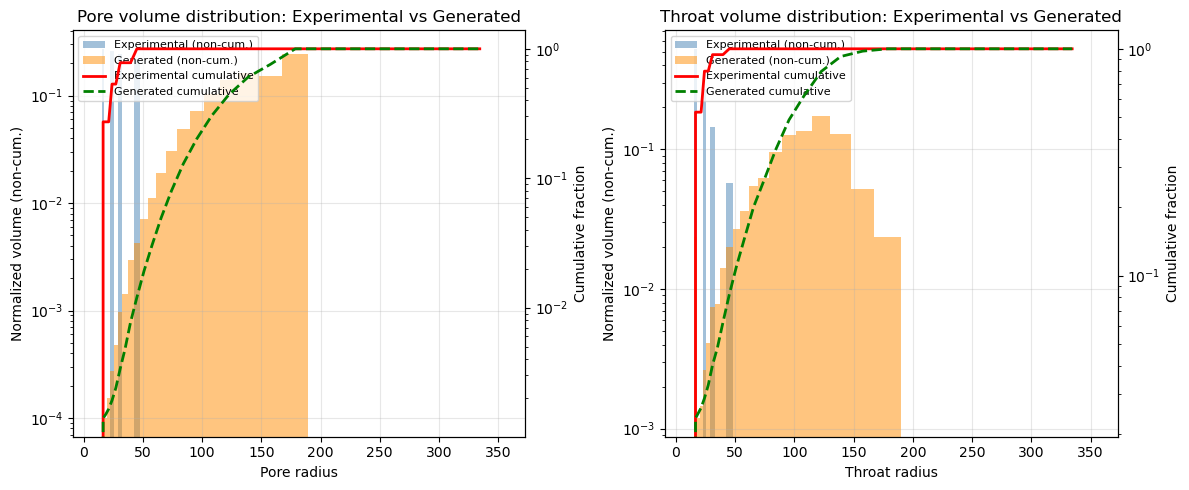

In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# --- Pore distribution comparison ---
# Left axis: non-cumulative volume distribution (bars)
# Right axis: cumulative distribution (line)
bars1 = ax1.bar(midradii, pore_hist_norm, width=deltaR, alpha=0.5,
                label='Experimental (non-cum.)', color='steelblue')
bars2 = ax1.bar(midradii, pore_dist_norm, width=deltaR, alpha=0.5,
                label='Generated (non-cum.)', color='darkorange')
ax1_cum = ax1.twinx()
line1, = ax1_cum.plot(midradii, pore_cumdist, 'r-', lw=2,
                      label='Experimental cumulative')
line2, = ax1_cum.plot(midradii, np.cumsum(pore_dist_norm), 'g--', lw=2,
                      label='Generated cumulative')
ax1.set_xlabel('Pore radius')
ax1.set_ylabel('Normalized volume (non-cum.)', color='black')
ax1_cum.set_ylabel('Cumulative fraction', color='black')
ax1.set_title('Pore volume distribution: Experimental vs Generated')
ax1.set_yscale('log')
ax1_cum.set_yscale('log')
ax1.grid(True, alpha=0.3)
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax1_cum.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc='upper left', fontsize=8)

# --- Throat distribution comparison ---
bars3 = ax2.bar(midradii, throat_hist_norm, width=deltaR, alpha=0.5,
                label='Experimental (non-cum.)', color='steelblue')
bars4 = ax2.bar(midradii, throat_dist_norm, width=deltaR, alpha=0.5,
                label='Generated (non-cum.)', color='darkorange')
ax2_cum = ax2.twinx()
line3, = ax2_cum.plot(midradii, throat_cumdist, 'r-', lw=2,
                      label='Experimental cumulative')
line4, = ax2_cum.plot(midradii, np.cumsum(throat_dist_norm), 'g--', lw=2,
                      label='Generated cumulative')
ax2.set_xlabel('Throat radius')
ax2.set_ylabel('Normalized volume (non-cum.)', color='black')
ax2_cum.set_ylabel('Cumulative fraction', color='black')
ax2.set_title('Throat volume distribution: Experimental vs Generated')
ax2.set_yscale('log')
ax2_cum.set_yscale('log')
ax2.grid(True, alpha=0.3)
h1, l1 = ax2.get_legend_handles_labels()
h2, l2 = ax2_cum.get_legend_handles_labels()
ax2.legend(h1 + h2, l1 + l2, loc='upper left', fontsize=8)

plt.tight_layout()
plt.show()


## 7. Mercury Intrusion Simulation




We run a mercury intrusion simulation on the generated network and compare
the intrusion curve against the experimental data.

Note: experimental diameters are converted to radii (diameter / 2) for comparison.



In [12]:
# Run mercury intrusion on the generated network
print("Running mercury intrusion simulation...")
Dlist, vint = mercury_intrusion(
    pn,
    faces=("x-", "x+", "y-", "y+", "z-", "z+"),
    D_ratio=1.2,
    Dmax=10.0,
    Dmin=0.01,
    verbose=False,
)

print(f"Intrusion steps: {len(Dlist)}")
print(f"Total intruded volume: {sum(vint):.6f}")

# Normalize by total void volume
total_void = pn.pores_volume + pn.throats_volume
print(f"Total void volume: {total_void:.6f}")
print(f"Intrusion fraction: {sum(vint) / total_void:.4f}")


Running mercury intrusion simulation...
Filling pores with entrance diameter >= 1.00e+01.
-Iteration 1    , Volume: 2.71e+10, pores filled: 5000 , throats filled 9461  
Filling pores with entrance diameter >= 8.33e+00.
Filling pores with entrance diameter >= 6.94e+00.
Filling pores with entrance diameter >= 5.79e+00.
Filling pores with entrance diameter >= 4.82e+00.
Filling pores with entrance diameter >= 4.02e+00.
Filling pores with entrance diameter >= 3.35e+00.
Filling pores with entrance diameter >= 2.79e+00.
Filling pores with entrance diameter >= 2.33e+00.
Filling pores with entrance diameter >= 1.94e+00.
Filling pores with entrance diameter >= 1.62e+00.
Filling pores with entrance diameter >= 1.35e+00.
Filling pores with entrance diameter >= 1.12e+00.
Filling pores with entrance diameter >= 9.35e-01.
Filling pores with entrance diameter >= 7.79e-01.
Filling pores with entrance diameter >= 6.49e-01.
Filling pores with entrance diameter >= 5.41e-01.
Filling pores with entrance dia

### Plot experimental vs simulated intrusion curves



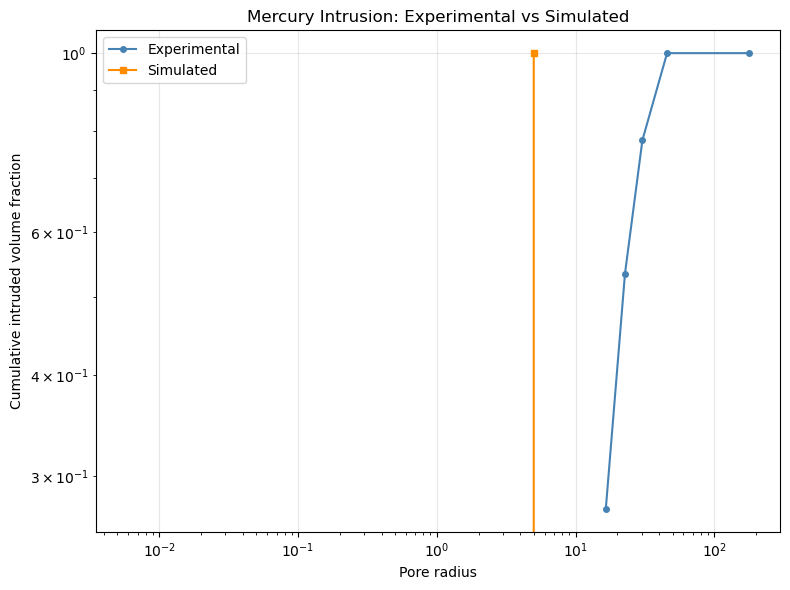

In [13]:
# Experimental intrusion: volume vs diameter (convert diameter -> radius)
exp_radii = diameters_f / 2.0
exp_cum_vol = np.cumsum(volumes_f) / volumes_f.sum()

# Simulated intrusion: Dlist contains diameters, convert to radius
sim_radii = np.array(Dlist[::-1]) / 2.0  # reverse order (smallest first)
sim_cum_vol = np.cumsum(np.array(vint[::-1])) / total_void

fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(exp_radii, exp_cum_vol, 'o-', label='Experimental', color='steelblue', markersize=4)
ax.plot(sim_radii, sim_cum_vol, 's-', label='Simulated', color='darkorange', markersize=4)

ax.set_xlabel('Pore radius')
ax.set_ylabel('Cumulative intruded volume fraction')
ax.set_title('Mercury Intrusion: Experimental vs Simulated')
ax.legend()
ax.grid(True, alpha=0.3)
ax.set_xscale('log')
ax.set_yscale('log')

plt.tight_layout()
plt.show()


## 8. 3D Visualization




We visualize the generated network using the fast `Fast3DViewer` (suitable for
large networks) and save a JPEG image of the 3D view.



In [14]:
from pnm.Visualization import Fast3DViewer, vtk_viewer

# Visualize and save image
img_filename = NETWORKS_DIR / f"generated-NP{npores}-view.jpg"

print("Creating 3D visualization...")
vtk_viewer(
    pn,
    save=True,
    render=False,        # set True for interactive window
    camera=(20, 30),
    cmap='viridis',
    filename=str(img_filename),
    resolution=8,
    attr='radius',
)
print(f"3D image saved to: {img_filename}")

# Also create an interactive viewer (commented out - uncomment to use)
# viewer = Fast3DViewer(pn)
# viewer.render(resolution=8)
# viewer.interact(azimuth=20, elevation=30)


Creating 3D visualization...
Creating pore glyph actor (resolution=8)


3D image saved to: /home/jlux/Nextcloud/Codes/python3/pnm/examples/networks/generated-NP5000-view.jpg


## Summary




This notebook demonstrated the complete workflow:

1. ✅ Read experimental MIP data from CSV files
2. ✅ Compute pore diameter threshold and cumulative pore/throat distributions
3. ✅ Define model parameters (npores, e, PRTRR, sratio, minc, maxc)
4. ✅ Generate a random pore network using the fast cell-list packing
5. ✅ Compare experimental vs generated pore and throat distributions
6. ✅ Run mercury intrusion simulation and compare intrusion curves
7. ✅ Visualize the network in 3D and save an image

The generated network has been saved to `examples/networks/`.

